# Force field learning in a modular network: what changes from NF to FF?

Compares a network at the **end of null field (NF) training** with the same network at the **end of
force field (FF) learning**. Run the training script first (`go_3module_FF.py` or `go_4module_FF.py`):
it saves both sets of weights. After the main NF training the script fixes some of the weights
(`model.freeze`), so FF learning can only change the rest.

Three questions:

- **(a)** How much did the weights of each module change?
- **(b)** During preparation (target onset to go cue): which modules changed their activity, by how much, and how?
- **(c)** During movement: the same.

In [1]:
%matplotlib widget
import json
import numpy as np
import torch as th
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

from reaching_model import ReachingModel
from my_utils import model_path

def rms(x, axis=None):
    return np.sqrt(np.mean(x ** 2, axis=axis))

In [2]:
# LOAD THE NETWORK AT THE END OF NF TRAINING AND AT THE END OF FF LEARNING
MODEL_NAME = "my_4mod_FF"
N_PCS = 6             # number of PCs used to compare subspaces
MOVE_DURATION = 1.0   # length of the movement epoch, from the go cue (s)

model_NF = ReachingModel.load(MODEL_NAME, checkpoint="NF")   # end of NF training
model_FF = ReachingModel.load(MODEL_NAME)                    # end of FF learning
with open(model_path(MODEL_NAME, "phases.json")) as f:
    FF_STRENGTH = json.load(f)['ff_strength']                # strength of the curl field the network learned

policy = model_FF.policy
module_names = model_FF.config.module_names
print(model_FF)

Loaded model 'my_4mod_FF' (batches trained: 16000), with the weights of checkpoint 'NF'
Loaded model 'my_4mod_FF' (batches trained: 16000)
ReachingModel 'my_4mod_FF'
  Architecture: [premotor(128), motor(128), sensory(64), spinal(32)]
  Episode duration: 3.0s
  Batches trained: 16000
  Frozen weights: [{'connections': [['spinal', 'motor'], ['spinal', 'sensory'], ['spinal', 'spinal']], 'inputs': True, 'outputs': True, 'hidden_biases': True}]
  Directory: my_4mod_FF/


Testing 'my_4mod_FF' on center-out task (8 targets, FF=0)


Testing 'my_4mod_FF' on center-out task (8 targets, FF=10.0)
Testing 'my_4mod_FF' on center-out task (8 targets, FF=0)


Testing 'my_4mod_FF' on center-out task (8 targets, FF=10.0)
Testing 'my_4mod_FF' on center-out task (8 targets, FF=0)


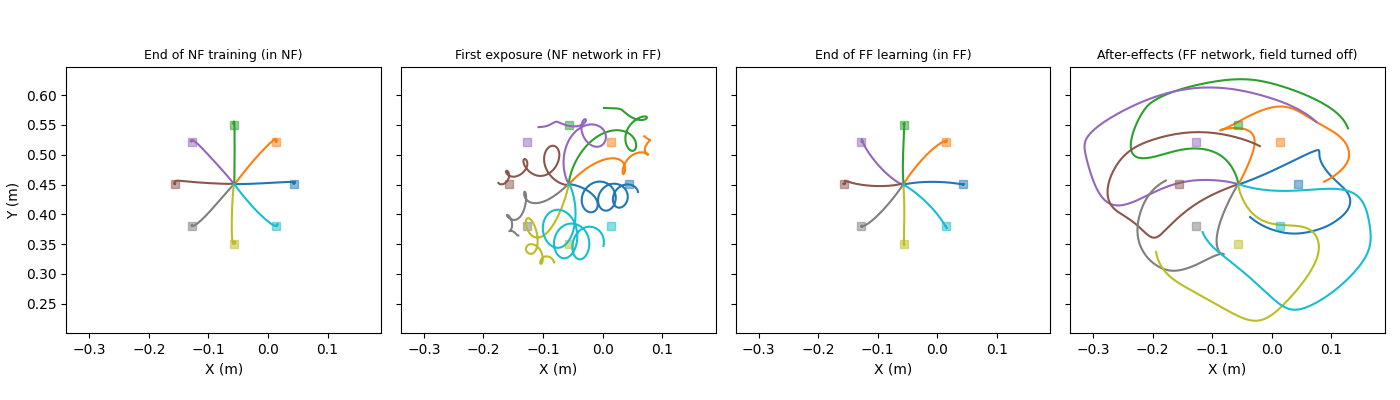

In [3]:
# CENTER-OUT TESTS (8 directions): each network, with and without the force field
def run_test(model, ff_strength):
    with th.no_grad():
        return model.test(n_targets=8, ff_strength=ff_strength, save_plots=False, save_data=False)

episode_NF = run_test(model_NF, 0)
episode_FF = run_test(model_FF, FF_STRENGTH)
episode_NF_repeat = run_test(model_NF, 0)   # a second NF test: how much do two tests differ when nothing was learned?
episodes = {
    'End of NF training (in NF)': episode_NF,
    'First exposure (NF network in FF)': run_test(model_NF, FF_STRENGTH),
    'End of FF learning (in FF)': episode_FF,
    'After-effects (FF network, field turned off)': run_test(model_FF, 0),
}

n_dirs = episode_NF['xy'].shape[0]
dir_colors = plt.cm.tab10(np.linspace(0, 1, n_dirs))   # one color per reach direction, used throughout

fig, axes = plt.subplots(1, 4, figsize=(14, 4), sharex=True, sharey=True)
for ax, (title, episode) in zip(axes, episodes.items()):
    for d in range(n_dirs):
        ax.plot(episode['xy'][d, :, 0], episode['xy'][d, :, 1], color=dir_colors[d])
        ax.plot(episode['targets'][d, -1, 0], episode['targets'][d, -1, 1], 's', color=dir_colors[d], alpha=0.5)
    ax.set_title(title, fontsize=9)
    ax.set_xlabel('X (m)')
    ax.set_aspect('equal', adjustable='box')
axes[0].set_ylabel('Y (m)')
plt.tight_layout()
plt.show()

## (a) How much did the weights of each module change?

The RMS change in each group of weights from NF to FF, as a % of the RMS of the NF weights (the three GRU
gates together, existing connections only). Each row shows the weights *onto* one module, by where they
come from. Blank = no such connections; "fixed" = frozen by the training script.

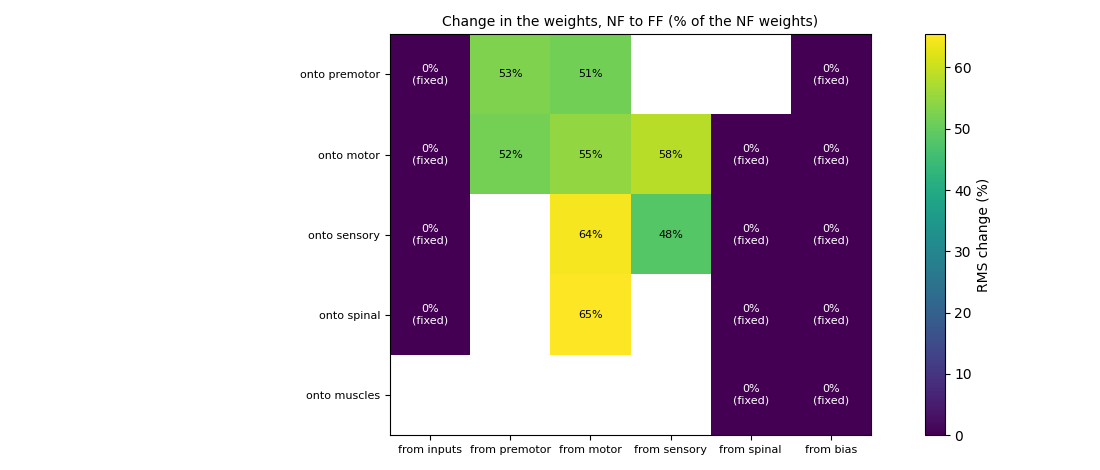

In [4]:
# The four things needed about every weight: its NF value, its FF value, whether the connection exists,
# and whether it could learn. (The connection masks are saved with the weights, as mask_<name>.)
w_NF, w_FF = model_NF.policy.state_dict(), policy.state_dict()
sources = [(w_NF, ''), (w_FF, ''), (w_FF, 'mask_'), (policy.trainable, '')]

# Weights onto the hidden units: (gate, receiving unit, sender), where the senders are the inputs, then the
# hidden units, then the bias. Weights onto the muscles: (1, muscle, sender), senders = hidden units, then bias.
gates = [('Wz', 'bz'), ('Wr', 'br'), ('Wh', 'bh')]
onto_hidden = [np.stack([np.column_stack([s[p + W], s[p + b]]) for W, b in gates]) for s, p in sources]
onto_muscles = [np.column_stack([s[p + 'Y'], s[p + 'bY']])[None] for s, p in sources]

n_in, n_hidden = policy.input_size, policy.hidden_size
sender_names = ['inputs'] + module_names + ['bias']
hidden_senders = [np.arange(n_in)] + [dims + n_in for dims in policy.module_dims] + [[n_in + n_hidden]]
muscle_senders = [[]] + policy.module_dims + [[n_hidden]]     # no connections from the inputs to the muscles
receiver_names = module_names + ['muscles']

change = np.full((len(receiver_names), len(sender_names)), np.nan)   # RMS change (%)
fixed = np.zeros(change.shape, dtype=bool)                           # were these weights fixed?
for i in range(len(receiver_names)):
    for j in range(len(sender_names)):
        if receiver_names[i] == 'muscles':
            nf, ff, exists, trainable = (a[:, :, muscle_senders[j]] for a in onto_muscles)
        else:
            nf, ff, exists, trainable = (a[:, policy.module_dims[i]][:, :, hidden_senders[j]] for a in onto_hidden)
        exists = exists == 1
        if exists.any():
            change[i, j] = 100 * rms((ff - nf)[exists]) / rms(nf[exists])
            fixed[i, j] = not trainable[exists].any()

fig, ax = plt.subplots(figsize=(1.5 * len(sender_names) + 2, 0.7 * len(receiver_names) + 1.2))
im = ax.imshow(change, cmap='viridis', vmin=0)
for (i, j), value in np.ndenumerate(change):
    if not np.isnan(value):
        ax.text(j, i, f"{value:.0f}%" + ("\n(fixed)" if fixed[i, j] else ""), ha='center', va='center',
                fontsize=8, color='k' if value > 0.6 * np.nanmax(change) else 'w')
ax.set_xticks(range(len(sender_names)), [f'from {name}' for name in sender_names], fontsize=8)
ax.set_yticks(range(len(receiver_names)), [f'onto {name}' for name in receiver_names], fontsize=8)
ax.set_title('Change in the weights, NF to FF (% of the NF weights)', fontsize=10)
fig.colorbar(im, ax=ax, label='RMS change (%)')
plt.tight_layout()
plt.show()

## (b, c) How did the activity of each module change?

Two tests are compared, direction by direction (the timing of test trials is fixed, so they line up in time):
**NF** = the network at the end of NF training, reaching in the null field; **FF** = the network at the end
of FF learning, reaching in the force field. Both make roughly straight reaches (see the hand paths above).

- **preparation**: from target onset to the go cue. The hand is still and the force field is off, so both
  networks receive the same inputs: any difference in activity is due to the change in the weights alone.
- **movement**: from the go cue, for `MOVE_DURATION` seconds. Here the force field is on in the FF test.

The activity of a module is split into the part that is **common to all directions** (the mean across
reach directions at each timestep) and the **direction-specific** rest. The PCA is done on the
direction-specific part.

In [5]:
def split_activity(episode):
    """The hidden activity of each module, split into the part common to all directions and the
    direction-specific rest: {'common': {module: (time, 1, units)}, 'specific': {module: (time, direction, units)}}."""
    h = episode['hidden'].numpy().transpose(1, 0, 2)     # (time, direction, units)
    activity = {'common': {}, 'specific': {}}
    for name, dims in zip(module_names, policy.module_dims):
        activity['common'][name] = h[:, :, dims].mean(axis=1, keepdims=True)
        activity['specific'][name] = h[:, :, dims] - activity['common'][name]
    return activity

NF = split_activity(episode_NF)
FF = split_activity(episode_FF)
NF_repeat = split_activity(episode_NF_repeat)

dt = episode_NF['dt']
tg_step = int(episode_NF['delay_tg_times'][0])   # target onset and go cue: the same for every test trial
go_step = int(episode_NF['delay_go_times'][0])
epochs = {'preparation': slice(tg_step, go_step),
          'movement': slice(go_step, go_step + int(MOVE_DURATION / dt))}
epoch_colors = {'preparation': 'tab:blue', 'movement': 'tab:orange'}

# The unit for all changes in activity: how strongly the module's NF activity varies with reach direction
modulation = {name: rms(NF['specific'][name]) for name in module_names}

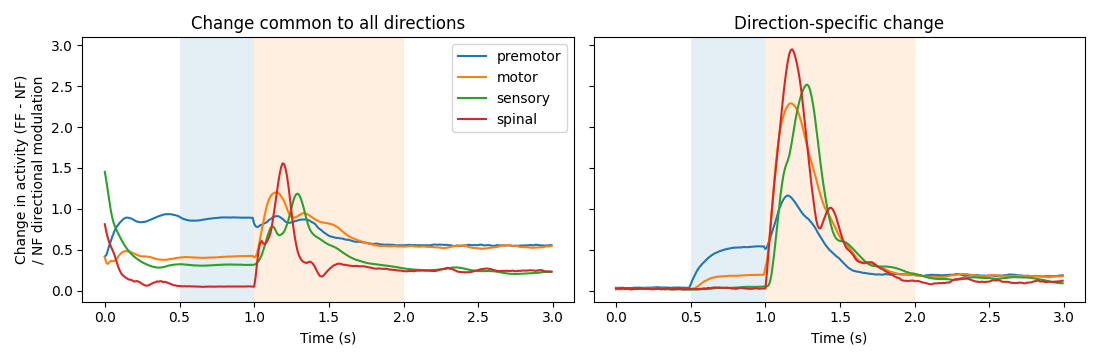

In [6]:
# WHEN DOES THE ACTIVITY CHANGE?
# The size of the change (FF - NF) at each timestep. Shaded: the preparation and movement epochs.

time = np.arange(episode_NF['hidden'].shape[1]) * dt
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharex=True, sharey=True)
for ax, part in zip(axes, ('common', 'specific')):
    for name in module_names:
        ax.plot(time, rms(FF[part][name] - NF[part][name], axis=(1, 2)) / modulation[name], label=name)
    for epoch, steps in epochs.items():
        ax.axvspan(steps.start * dt, steps.stop * dt, color=epoch_colors[epoch], alpha=0.12, lw=0)
    ax.set_xlabel('Time (s)')
axes[0].set_title('Change common to all directions')
axes[1].set_title('Direction-specific change')
axes[0].set_ylabel('Change in activity (FF - NF)\n/ NF directional modulation')
axes[0].legend()
plt.tight_layout()
plt.show()

### Which modules changed, by how much, and how?

For each module and epoch. *By how much* (in units of the module's NF directional modulation):

- **common shift**: the change in the activity common to all directions
- **direction-specific change**: the change in the direction-specific activity

*How* the direction-specific activity changed:

- **gain**: the strength of the directional modulation, FF relative to NF (1 = unchanged)
- **pattern correlation**: between the NF and FF patterns across units, directions and time
  (1 = the same pattern; lower = units changed their tuning or timing)
- **subspace overlap**: the FF variance captured by the first `N_PCS` NF PCs, relative to the first `N_PCS`
  FF PCs (1 = the activity stays in the same dimensions; lower = it moves into new dimensions)

The black ticks are the same measures between two NF tests of the same network: the difference expected
from noise alone.

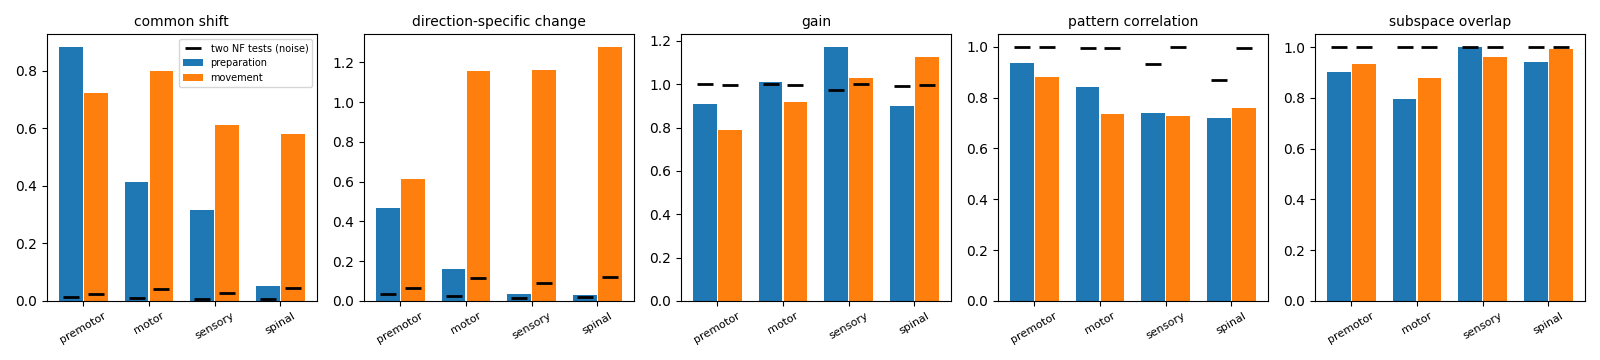

columns: common shift, direction-specific change, gain, pattern correlation, subspace overlap
preparation premotor  0.88 (0.01)   0.46 (0.03)   0.91 (1.00)   0.94 (1.00)   0.90 (1.00)
preparation motor     0.41 (0.01)   0.16 (0.02)   1.01 (1.00)   0.84 (1.00)   0.80 (1.00)
preparation sensory   0.31 (0.01)   0.03 (0.02)   1.17 (0.97)   0.74 (0.93)   1.00 (1.00)
preparation spinal    0.05 (0.01)   0.03 (0.02)   0.90 (0.99)   0.72 (0.87)   0.94 (1.00)
movement    premotor  0.72 (0.02)   0.61 (0.07)   0.79 (1.00)   0.88 (1.00)   0.93 (1.00)
movement    motor     0.80 (0.04)   1.16 (0.11)   0.92 (1.00)   0.74 (1.00)   0.88 (1.00)
movement    sensory   0.61 (0.03)   1.16 (0.09)   1.03 (1.00)   0.73 (1.00)   0.96 (1.00)
movement    spinal    0.58 (0.05)   1.28 (0.12)   1.12 (1.00)   0.76 (1.00)   0.99 (1.00)


In [7]:
measures = ['common shift', 'direction-specific change', 'gain', 'pattern correlation', 'subspace overlap']

def variance_captured(data, fit_on):
    """The variance of data (samples, units) along the first N_PCS PCs of fit_on."""
    return np.sum((data @ PCA(N_PCS).fit(fit_on).components_.T) ** 2)

def compare(a, b):
    """The measures above, comparing test b with test a: {epoch: {module: {measure: value}}}."""
    result = {}
    for epoch, steps in epochs.items():
        result[epoch] = {}
        for name in module_names:
            n_units = a['specific'][name].shape[-1]
            specific_a = a['specific'][name][steps].reshape(-1, n_units)   # (time x direction, units)
            specific_b = b['specific'][name][steps].reshape(-1, n_units)
            result[epoch][name] = {
                'common shift': rms(b['common'][name][steps] - a['common'][name][steps]) / modulation[name],
                'direction-specific change': rms(specific_b - specific_a) / modulation[name],
                'gain': rms(specific_b) / rms(specific_a),
                'pattern correlation': np.sum(specific_a * specific_b) / np.sqrt(np.sum(specific_a ** 2) * np.sum(specific_b ** 2)),
                'subspace overlap': variance_captured(specific_b, specific_a) / variance_captured(specific_b, specific_b),
            }
    return result

learning = compare(NF, FF)         # NF vs FF
noise = compare(NF, NF_repeat)     # NF vs a second NF test

x = np.arange(len(module_names))
fig, axes = plt.subplots(1, len(measures), figsize=(3.2 * len(measures), 3.6))
for ax, measure in zip(axes, measures):
    for k, epoch in enumerate(epochs):
        offset = (k - 0.5) * 0.38
        ax.bar(x + offset, [learning[epoch][name][measure] for name in module_names], width=0.36,
               color=epoch_colors[epoch], label=epoch)
        ax.plot(x + offset, [noise[epoch][name][measure] for name in module_names], 'k_', ms=12, mew=2,
                label='two NF tests (noise)' if k == 0 else None)
    ax.set_xticks(x, module_names, rotation=30, fontsize=8)
    ax.set_title(measure, fontsize=10)
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

# The same numbers: NF vs FF (and NF vs NF, in brackets)
print("columns: " + ", ".join(measures))
for epoch in epochs:
    for name in module_names:
        values = [f"{learning[epoch][name][m]:.2f} ({noise[epoch][name][m]:.2f})" for m in measures]
        print(f"{epoch:12s}{name:10s}" + "   ".join(values))

A high subspace overlap with a low pattern correlation means the activity was rearranged *within* the same
dimensions. A module whose bar is at its black tick did not change.

### What do the changes look like in PC space?

The direction-specific activity of each module, projected onto its first two PCs. The PCs are computed
from the NF and FF activity of the epoch together, so both are shown in exactly the same space
(top row: NF, bottom row: FF). Each line is one reach direction, from the start of the epoch to its end (dot).

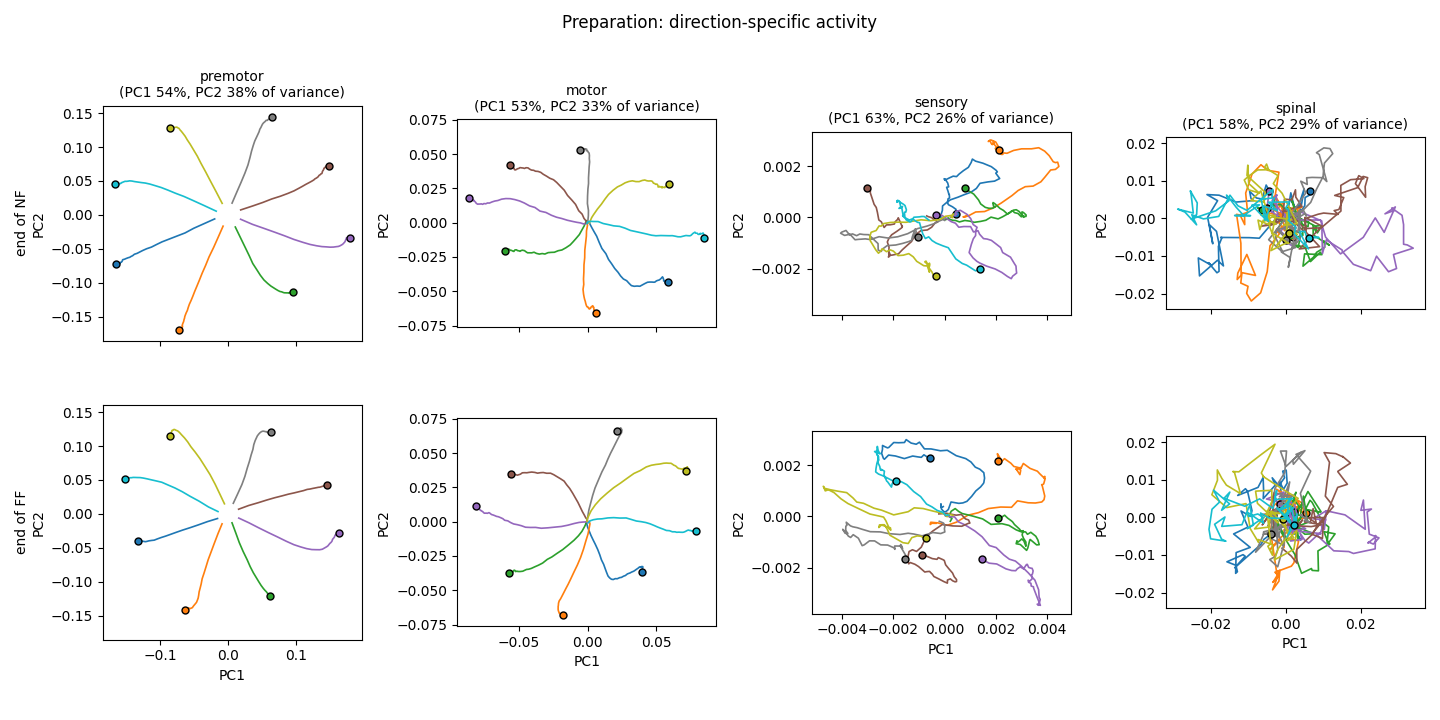

In [8]:
def plot_epoch(epoch):
    steps = epochs[epoch]
    fig, axes = plt.subplots(2, len(module_names), figsize=(3.6 * len(module_names), 7.2), sharex='col', sharey='col')
    for col, name in enumerate(module_names):
        specific_NF, specific_FF = NF['specific'][name][steps], FF['specific'][name][steps]   # (time, direction, units)
        both = np.concatenate([specific_NF, specific_FF])
        pca = PCA(2).fit(both.reshape(-1, both.shape[-1]))
        for ax, specific in zip(axes[:, col], (specific_NF, specific_FF)):
            pcs = specific @ pca.components_.T                                                 # (time, direction, 2)
            for d in range(n_dirs):
                ax.plot(pcs[:, d, 0], pcs[:, d, 1], color=dir_colors[d], lw=1.2)
                ax.plot(pcs[-1, d, 0], pcs[-1, d, 1], 'o', color=dir_colors[d], ms=5, mec='k')
            ax.set_aspect('equal', adjustable='box')
            ax.set_ylabel('PC2')
        var = pca.explained_variance_ratio_ * 100
        axes[0, col].set_title(f'{name}\n(PC1 {var[0]:.0f}%, PC2 {var[1]:.0f}% of variance)', fontsize=10)
        axes[1, col].set_xlabel('PC1')
    axes[0, 0].set_ylabel('end of NF\nPC2')
    axes[1, 0].set_ylabel('end of FF\nPC2')
    fig.suptitle(f'{epoch.capitalize()}: direction-specific activity', fontsize=12)
    plt.tight_layout()
    plt.show()

# (b) PREPARATION: target onset to go cue
plot_epoch('preparation')

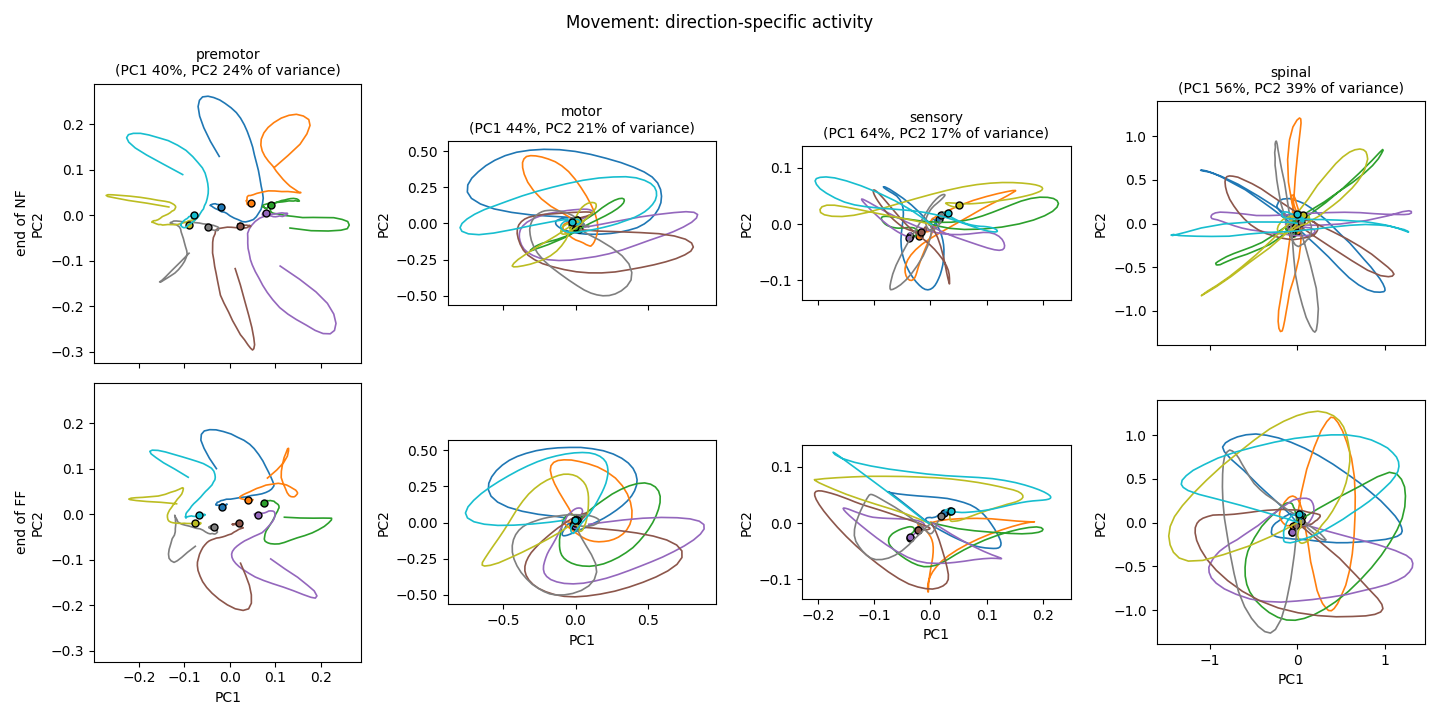

In [9]:
# (c) MOVEMENT: from the go cue, for MOVE_DURATION seconds
plot_epoch('movement')